# Noms du binome: 

FERNANDES--STRAG, TORRES--LEGUET

# Prénoms du binome:

Henry, Alexandre

## Note: exporter le compte rendu basé sur le notebook au format pdf


# Estimation et détection de l'empreinte de la caméra (PRNU)
* L'objectif de ce TP est d'utiliser l'estimation mathématique du PRNU du cours et de la mettre en oeuvre.  Puisque vous travaillez en binôme, décidez de l'appareil photo que vous utiliserez (la méthode devrait fonctionner pour les deux, donc n'hésitez pas à tester l'autre appareil également).

Nous utilisons les 30 images du ciel comme « training set » pour l'estimation du PRNU.
* Après avoir obtenu l'estimation K du PRNU, nous vérifions si nous pouvons détecter le PRNU dans d'autres images (de test).
* À la fin, nous utiliserons diverses opérations de traitement d'image sur les images de test et vérifierons si le PRNU peut toujours être détecté.

Nous chercherons aussi à comprendre (voir dernière question):
- Comment supprimer notre PRNU de nos images ? Pourquoi voudrions-nous faire cela ? Rappelons que $W=I-D(I)=IK+\Theta$, où $D(\cdot)$ est une fonction de débruitage, et $\Theta$ est le bruit.
- En ayant le PRNU $K_{target}$ d'une personne, comment pouvons-nous nous faire passer pour elle et injecter son PRNU dans une image $I$ avec un PRNU différent $K$ ? 

**Il est important de commenter vos réponses, en utilisant des cellules markdown**


In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from PIL import Image
import os
from tqdm import tqdm
from scipy.signal import wiener
from numpy.fft import fft2, ifft2
from scipy.ndimage import gaussian_filter

In [3]:
def rgb2gray(im: np.ndarray) -> np.ndarray:
    """
    :param im : tableau multidimensionnel
    :return : version en niveaux de gris de l'entrée im
    """
    rgb2gray_vector = np.asarray([0.29893602, 0.58704307, 0.11402090]).astype(np.float32)
    rgb2gray_vector.shape = (3, 1)

    if im.ndim == 2:
        im_gray = np.copy(im)
    elif im.shape[2] == 1:
        im_gray = np.copy(im[:, :, 0])
    elif im.shape[2] == 3:
        w, h = im.shape[:2]
        im = np.reshape(im, (w * h, 3))
        im_gray = np.dot(im, rgb2gray_vector)
        im_gray.shape = (w, h)
    else:
        raise ValueError("L'image d'entrée doit avoir 1 ou 3 canaux")

    return im_gray.astype(np.float32)

#### Estimation du PRNU : utilisation des images d'entraînement du ciel
* Nous n'avons pas discuté de ce qu'il faut faire avec les canaux de couleur. Nous allons donc d'abord transformer chaque image que nous utilisons en niveaux de gris en utilisant la fonction `rgb2gray()`.
* Si l'une des images d'entraînement est saturée (avec des pixels égaux à 0 ou 255), ne l'utilisez pas pour l'estimation (ignorez-la simplement). Affichez le nom de l'image si cela se produit
* Utiliser la fonction de débruitage `scipy.signal.wiener`.

In [ ]:
img_folder = 'train_images_alex/'
imnames = [f for f in os.listdir(img_folder) if f.endswith('.png')]

im_size = np.array(np.array(Image.open(img_folder+imnames[0])).shape)[:2]
print(im_size)
K = np.zeros(im_size)

[3024 4032]


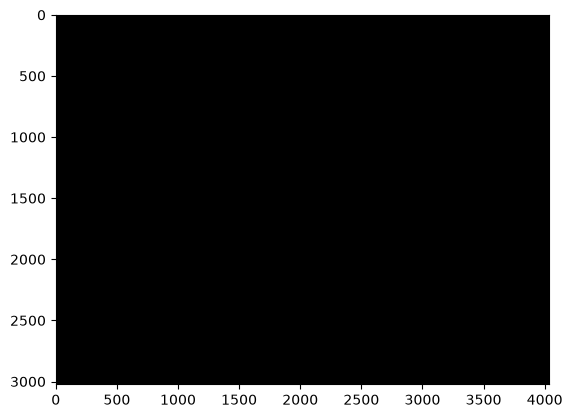

In [6]:
plt.imshow(K, cmap='gray')

Q : L'estimation du PRNU peut être biaisée en raison du démosaïquage et d'autres opérations de la caméra. Écrivez une fonction qui mettra à zéro la moyenne de chaque colonne et de chaque ligne du PRNU (vous pouvez le faire de manière séquentielle, d'abord les colonnes, puis les lignes).

In [358]:
def PRNU_process(K):
    PRNU = np.copy(K)
    ...
    return PRNU

Q : Enlever le biais de l'estimation `K` en utilisant la fonction `PRNU_process()` et tracer l'histogramme des nouvelles valeurs. Les valeurs exigibles doivent être comprises entre $-10^{-2}$ et $10^{-2}$ (ou inférieures).

Q : Montrez la partie supérieure gauche de $200\times 200$ pixels du PRNU comme une image en niveaux de gris.

In [ ]:
plt.figure(figsize=(10,10))


#### Détection du PRNU : utilisation des images de test
* Utilisez les 6 images fournies pour le test
* Ajoutez l'une des images d'apprentissage à l'ensemble de test (pour vérifier que la méthode fonctionne).
* Ajoutez 2 autres images de votre appareil photo à l'ensemble de test. N'hésitez pas à prendre ces photos maintenant. Vous devriez avoir 9 images de test au total.
* Pour chaque image de test, calculez la valeur $NCC$ comme indiqué dans les slides. Utilisez la fonction `crosscorr_2d` fournie. L'image test et l'estimation PRNU peuvent avoir des tailles différentes. Ne considérons que leur intersection (la plus petite des deux tailles).
* Trouvez un pic dans la valeur $NCC$ : $(u,v)=\arg\max NCC$. En utilisant un petit voisinage de $5\times 5$ $\Lambda$ de ce pic, calculer la valeur $PCE$ comme indiqué sur les slides. Si le pic se trouve sur la frontière, recadrer le voisinage
* Stocker la valeur PCE pour chaque image testée. Elle devrait être de plusieurs milliers pour l'image d'apprentissage.

In [361]:
def crosscorr_2d(k1: np.ndarray, k2: np.ndarray) -> np.ndarray:
    """
    PRNU Corrélation croisée 2D
    :param k1 : matrice 2D de taille (h1,w1)
    :param k2 : matrice 2D de taille (h2,w2)
    :return : matrice 2D de taille (max(h1,h2),max(w1,w2))
    """
    assert (k1.ndim == 2)
    assert (k2.ndim == 2)

    max_height = max(k1.shape[0], k2.shape[0])
    max_width = max(k1.shape[1], k2.shape[1])

    k1 -= k1.flatten().mean()
    k2 -= k2.flatten().mean()

    k1 = np.pad(k1, [(0, max_height - k1.shape[0]), (0, max_width - k1.shape[1])], mode='constant', constant_values=0)
    k2 = np.pad(k2, [(0, max_height - k2.shape[0]), (0, max_width - k2.shape[1])], mode='constant', constant_values=0)

    k1_fft = fft2(k1, )
    k2_fft = fft2(np.rot90(k2, 2), )

    return np.real(ifft2(k1_fft * k2_fft)).astype(np.float32)

In [ ]:
img_folder = 'test_images/'
imnames = ... # 8 images (5 mine, 1 from training)
PCE = np.zeros((len(imnames)))


In [ ]:
for P, im in zip(PCE, imnames):
    print(P, im)

#### Détection du PRNU après traitement de l'image
* Pour chaque image testée, nous allons maintenant utiliser les opérations de traitement d'image suivantes (une à la fois) avant de détecter le PRNU estimé :
  * Rien
  * JPEG avec une qualité de compression de 90, 60 et 5 (utilisez `jpeg()`)
  * Correction gamma avec les valeurs gamma 0.1, 5 (utilisez `correction_gamma()`)
  * Filtre de Wiener
  * Recadrage des pixels de 1000 à 2000 dans les deux directions
  * Filtre gaussien avec une déviation standard de 5 pixels (utilisez `gaussian_filter()`)
  * Rotation de l'image de 5 degrés (utilisez `PIL.Image.rotate()`)
* Imprimez les résultats et les commentez

In [372]:
def jpeg(image, quality):
    Image.fromarray(np.uint8(image)).save('tmp.jpg', quality=quality)
    image = np.float32(np.array(Image.open('tmp.jpg')))
    os.remove('tmp.jpg')
    return image

def correction_gamma(image, gamma):
    gamma_corrige = np.array(255 * (image / 255) ** gamma)
    return gamma_corrige

In [373]:
traitements = ['', 'JPG90', 'JPG60', 'JPG5', 'gamma01', 'gamma5', 'wiener', 'recadrage', 'gauss5', 'rot5']

In [ ]:
PCE = np.zeros((len(traitements), len(imnames)))


In [ ]:
pd.DataFrame(PCE, columns=imnames, index=traitements)

Q : Quel seuil de décision pouvons-nous utiliser afin d'éviter les faux positifs (détecter des images provenant d'autres caméras comme des images provenant de votre caméra) et de maximiser la détection correcte ?

In [ ]:
# TO DO

Q : Choisissez l'une des images détectées comme provenant de votre appareil photo (à l'exception de celle utilisée pour l'apprentissage), et pour chaque opération de traitement, tracez un voisinage $200\times200$ de la corrélation croisée $NCC$ autour de son pic en 3D (envisagez d'utiliser `plot_surface()` de matplotlib). Commentez les résultats. Comment pouvons-nous modifier la détection pour détecter l'image tournée si nous décidons d'utiliser un seuil de 60 ?

In [ ]:
imname = ...


## Conclusions 

- Comment supprimer notre PRNU de nos images ? Pourquoi voudrions-nous faire cela ? Rappelons que $W=I-D(I)=IK+\Theta$, où $D(\cdot)$ est une fonction de débruitage, et $\Theta$ est le bruit.
- En ayant le PRNU $K_{target}$ d'une personne, comment pouvons-nous nous faire passer pour elle et injecter son PRNU dans une image $I$ avec un PRNU différent $K$ ? 

**To do**